# 04 — Bagging
Notebook thực nghiệm độc lập cho SecuraAI / Windows-APT 2025. Mọi lựa chọn được khóa bằng Train/Validation trước khi đánh giá Test.

## 0. Chuẩn bị môi trường
Chạy từ thư mục project hoặc thư mục `notebooks`. Không cần GPU.

In [1]:
from pathlib import Path
import json, hashlib
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import platform, sklearn
import importlib
from IPython.display import display
from sklearn.base import clone
from sklearn.metrics import (ConfusionMatrixDisplay, RocCurveDisplay, PrecisionRecallDisplay,
    accuracy_score, precision_score, recall_score, f1_score, fbeta_score, roc_auc_score,
    average_precision_score, confusion_matrix, make_scorer)
from sklearn.model_selection import GridSearchCV, StratifiedGroupKFold
from sklearn.dummy import DummyClassifier
from securaai_ml.data import load_training_data
import securaai_ml.modeling as modeling_module
importlib.reload(modeling_module)  # tránh module cache cũ khi source vừa được cập nhật
from securaai_ml.modeling import (candidate_factories, decision_scores, parameter_grids,
    teaching_candidate_factories, teaching_parameter_grids)
from securaai_ml.schema import MODEL_FEATURES, TARGET_COLUMN, GROUP_COLUMN
from securaai_ml.train import temporal_train_validation_test

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
data, audit = load_training_data(ROOT / 'data' / 'raw')
train, validation, test = temporal_train_validation_test(data)
X_train, y_train = train.loc[:, MODEL_FEATURES], train[TARGET_COLUMN]
X_validation, y_validation = validation.loc[:, MODEL_FEATURES], validation[TARGET_COLUMN]
groups = train[GROUP_COLUMN]
cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)
audit

DatasetAudit(rows=94365, malicious=58530, benign=35835, groups=36, invalid_timestamps=0)

### Tính tái lập
Cố định seed và in phiên bản. Đổi seed là một thí nghiệm mới, không chọn seed bằng kết quả Test.

In [2]:
import platform
import numpy as np
import matplotlib.pyplot as plt
import sklearn

SEED=42
np.random.seed(SEED)
plt.rcParams.update({'figure.dpi':110,'font.family':'DejaVu Sans','font.size':10})
print('Python:',platform.python_version(),'| sklearn:',sklearn.__version__,'| seed:',SEED)

Python: 3.13.15 | sklearn: 1.7.0 | seed: 42


## 1. Xác thực dữ liệu và ý nghĩa nhãn
Nhãn MALICIOUS_APT được suy ra từ MITRE/Wazuh tag, không phải ground truth do chuyên gia xét duyệt. Các cột tạo nhãn bị loại khỏi đầu vào.

In [3]:
display(pd.Series(audit.__dict__,name='value').to_frame())
assert audit.rows==len(data)
assert data[TARGET_COLUMN].nunique()==2
assert data[GROUP_COLUMN].ne('unknown-date').all()
print('Dataset checks passed')

,value
rows,94365
malicious,58530
benign,35835
groups,36
invalid_timestamps,0


Dataset checks passed


## 2. Chia Train/Validation/Test và dấu vân tay
Chia xấp xỉ 60/20/20 theo ngày; không có ngày nào xuất hiện ở hai tập.

In [4]:
split_table=pd.DataFrame([{'set':name,'rows':len(part),'benign':int((part[TARGET_COLUMN]==0).sum()),'malicious':int((part[TARGET_COLUMN]==1).sum()),'attack_rate':float(part[TARGET_COLUMN].mean()),'dates':part[GROUP_COLUMN].nunique()} for name,part in [('Train',train),('Validation',validation),('Test',test)]])
display(split_table)
assert set(train[GROUP_COLUMN]).isdisjoint(validation[GROUP_COLUMN])
assert set(train[GROUP_COLUMN]).isdisjoint(test[GROUP_COLUMN])
assert set(validation[GROUP_COLUMN]).isdisjoint(test[GROUP_COLUMN])
split_hash=hashlib.sha256(json.dumps({'train':sorted(train[GROUP_COLUMN].unique()),'validation':sorted(validation[GROUP_COLUMN].unique()),'test':sorted(test[GROUP_COLUMN].unique())},sort_keys=True).encode()).hexdigest()
print('Split hash:',split_hash[:16])

,set,rows,benign,malicious,attack_rate,dates
0,Train,59275,20029,39246,0.662100,31
1,Validation,20176,9118,11058,0.548077,2
2,Test,14914,6688,8226,0.551562,3


Split hash: c20123f0928c7b1d


## 3. EDA chỉ trên Train
Quan sát mất cân bằng và tỷ lệ tấn công theo nhóm sự kiện mà không dùng Test để định hướng mô hình.

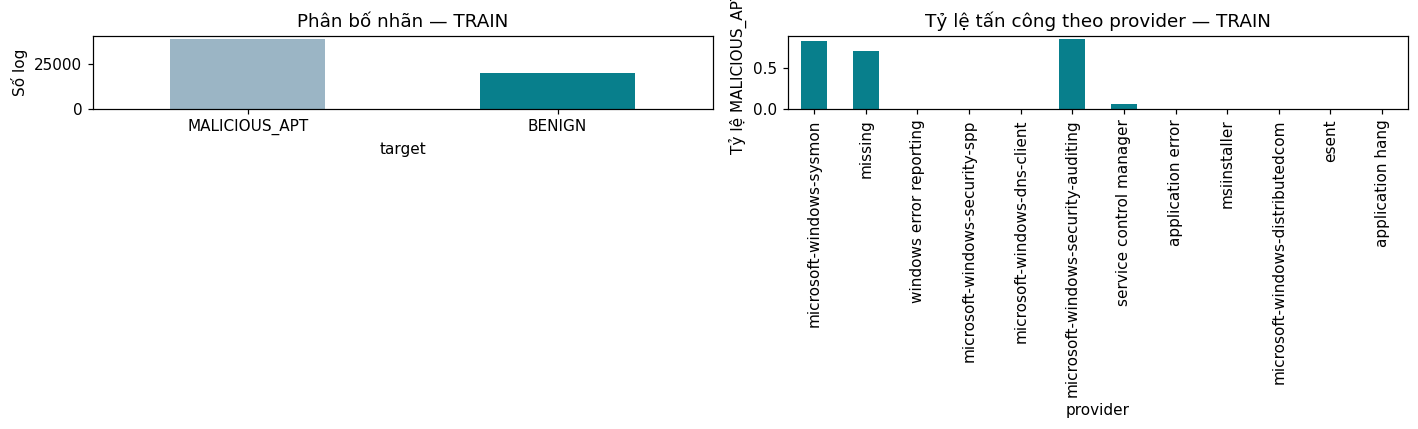

,count,mean
provider,,
microsoft-windows-sysmon,37046,0.841494
missing,8898,0.718588
windows error reporting,3138,0.000000
microsoft-windows-security-spp,2786,0.000000
microsoft-windows-dns-client,2672,0.000000
microsoft-windows-security-auditing,1779,0.866217
service control manager,899,0.058954
application error,525,0.000000
msiinstaller,404,0.000000


In [5]:
fig,ax=plt.subplots(1,2,figsize=(13,4))
train[TARGET_COLUMN].map({0:'BENIGN',1:'MALICIOUS_APT'}).value_counts().plot.bar(ax=ax[0],rot=0,color=['#9bb5c5','#087f8c']); ax[0].set_title('Phân bố nhãn — TRAIN'); ax[0].set_ylabel('Số log')
provider_rate=train.groupby('provider')[TARGET_COLUMN].agg(['count','mean']).query('count >= 100').sort_values('count',ascending=False).head(12)
provider_rate['mean'].plot.bar(ax=ax[1],color='#087f8c'); ax[1].set_title('Tỷ lệ tấn công theo provider — TRAIN'); ax[1].set_ylabel('Tỷ lệ MALICIOUS_APT')
plt.tight_layout(); plt.show(); display(provider_rate)

## 4. Cơ chế thuật toán và phạm vi triển khai
Huấn luyện nhiều cây trên các bootstrap sample rồi bỏ phiếu để giảm phương sai so với một cây đơn. Tuning số cây và tỷ lệ mẫu mỗi cây.

## 5. Tiền xử lý an toàn trong Pipeline
One-Hot Encoder được fit bên trong từng fold. Không fit preprocessing trên toàn bộ dữ liệu trước CV.

In [6]:
from sklearn import set_config
from IPython.display import display

set_config(display='diagram')
candidate=teaching_candidate_factories(SEED)['bagging']()
grid=teaching_parameter_grids()['bagging']

# Trong Jupyter, object Pipeline cuối cell được render thành sơ đồ HTML có thể mở rộng.
display(candidate)

grid_table=pd.DataFrame([
    {'hyperparameter':name, 'candidate_values':str(values), 'purpose':(
        'Giới hạn độ sâu, kiểm soát độ phức tạp' if 'max_depth' in name else
        'Số mẫu tối thiểu ở mỗi lá, hạn chế overfit' if 'min_samples_leaf' in name else
        'Giá trị được Grid Search thử nghiệm')}
    for name,values in grid.items()
])
display(grid_table)

,steps,"[('preprocess', ...), ('model', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('categorical', ...), ('numeric', ...)]"
,remainder,'drop'
,sparse_threshold,1.0
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


,hyperparameter,candidate_values,purpose
0,model__n_estimators,"[50, 100]",Giá trị được Grid Search thử nghiệm
1,model__max_samples,"[0.7, 1.0]",Giá trị được Grid Search thử nghiệm


## 6. Độ đo và Dummy baseline
Accuracy có thể gây hiểu nhầm. F2 nhấn mạnh Recall; ROC-AUC đo xếp hạng; AP hữu ích khi mất cân bằng.

In [7]:
dummy=DummyClassifier(strategy='prior').fit(X_train,y_train)
dummy_pred=dummy.predict(X_validation); dummy_score=dummy.predict_proba(X_validation)[:,1]
display(pd.Series({'accuracy':accuracy_score(y_validation,dummy_pred),'precision':precision_score(y_validation,dummy_pred,zero_division=0),'recall':recall_score(y_validation,dummy_pred,zero_division=0),'f1':f1_score(y_validation,dummy_pred,zero_division=0),'f2':fbeta_score(y_validation,dummy_pred,beta=2,zero_division=0),'roc_auc':roc_auc_score(y_validation,dummy_score),'average_precision':average_precision_score(y_validation,dummy_score)},name='Dummy — Validation').to_frame())

,Dummy — Validation
accuracy,0.548077
precision,0.548077
recall,1.000000
f1,0.708075
f2,0.858434
roc_auc,0.500000
average_precision,0.548077


## 7. Chọn siêu tham số bằng 5-Fold chỉ trên Train
Grid Search chấm F2, F1, ROC-AUC và AP; `refit='f2'` khóa tiêu chí lựa chọn trước khi xem Test.

In [8]:
model_name = 'bagging'
search = GridSearchCV(
    teaching_candidate_factories(42)[model_name](),
    teaching_parameter_grids()[model_name],
    scoring={'f2': make_scorer(fbeta_score, beta=2, zero_division=0),
             'f1': 'f1', 'roc_auc': 'roc_auc', 'average_precision': 'average_precision'},
    refit='f2',
    cv=cv, n_jobs=1, return_train_score=True,
)
search.fit(X_train, y_train, groups=groups)
print('Best parameters:', search.best_params_)
print('Mean CV F2:', search.best_score_)
model = search.best_estimator_

Best parameters: {'model__max_samples': 0.7, 'model__n_estimators': 100}
Mean CV F2: 0.986000561908449


In [9]:
cv_table=pd.DataFrame(search.cv_results_).sort_values('rank_test_f2')
display(cv_table[['params','mean_train_f2','mean_test_f2','std_test_f2','mean_test_roc_auc','mean_test_average_precision']].head(12))

,params,mean_train_f2,mean_test_f2,std_test_f2,mean_test_roc_auc,mean_test_average_precision
1,"{'model__max_samples': 0.7, 'model__n_estimato...",0.998206,0.986001,0.008788,0.993082,0.992057
0,"{'model__max_samples': 0.7, 'model__n_estimato...",0.998218,0.985994,0.008739,0.993106,0.992033
3,"{'model__max_samples': 1.0, 'model__n_estimato...",0.998195,0.985982,0.008758,0.993016,0.991905
2,"{'model__max_samples': 1.0, 'model__n_estimato...",0.998240,0.985973,0.008731,0.993040,0.991901


## 8. Đánh giá trên Validation
Confusion Matrix cho biết TN/FP/FN/TP. ROC và PR phải dùng score liên tục, không dùng nhãn 0/1 đã cắt.

,Validation
accuracy,0.980373
precision,0.999438
recall,0.964731
f1,0.981778
f2,0.971479
roc_auc,0.992827
average_precision,0.993410


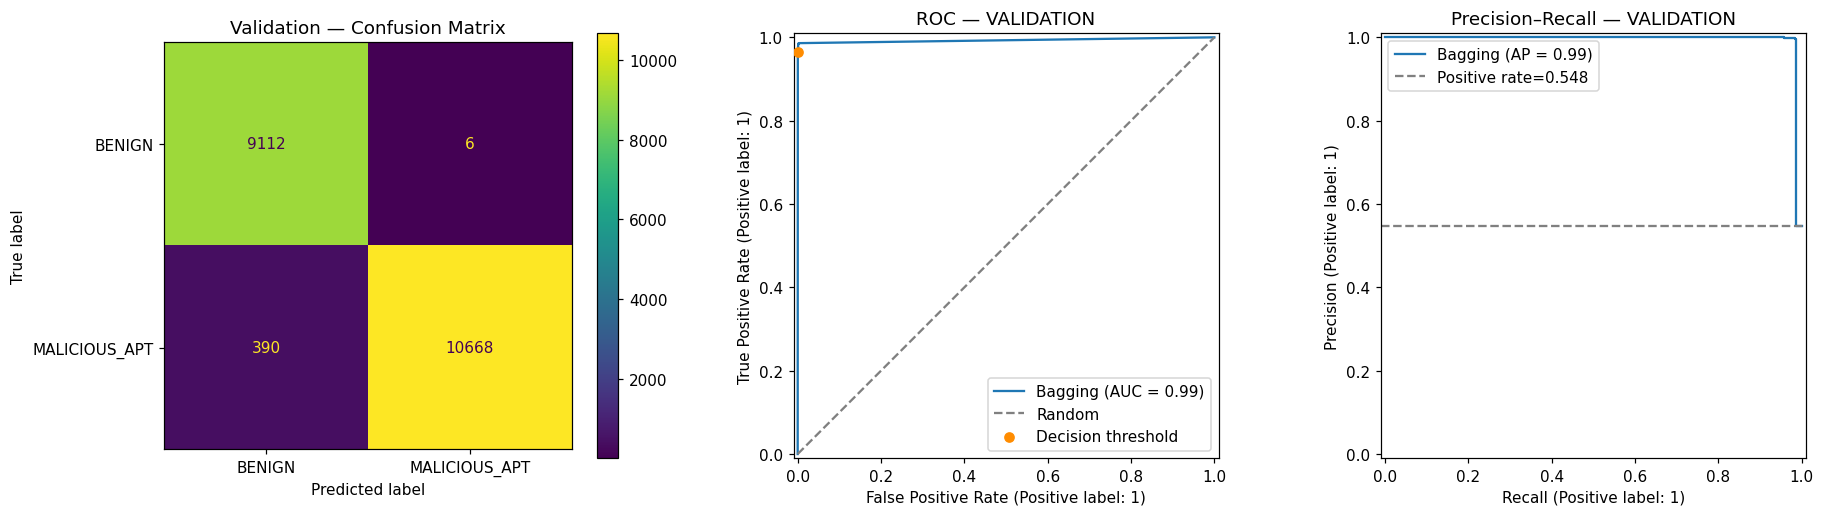

In [10]:
pred = model.predict(X_validation)
score = decision_scores(model, X_validation)
result = pd.Series({
    'accuracy': accuracy_score(y_validation, pred),
    'precision': precision_score(y_validation, pred, zero_division=0),
    'recall': recall_score(y_validation, pred, zero_division=0),
    'f1': f1_score(y_validation, pred, zero_division=0),
    'f2': fbeta_score(y_validation, pred, beta=2, zero_division=0),
    'roc_auc': roc_auc_score(y_validation, score),
    'average_precision': average_precision_score(y_validation, score),
})
display(result.to_frame('Validation'))
tn, fp, fn, tp = confusion_matrix(y_validation, pred, labels=[0, 1]).ravel()
fpr_at_threshold = fp / (fp + tn)
tpr_at_threshold = tp / (tp + fn)
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
ConfusionMatrixDisplay.from_predictions(y_validation, pred, display_labels=['BENIGN','MALICIOUS_APT'], ax=axes[0])
axes[0].set_title('Validation — Confusion Matrix')
RocCurveDisplay.from_predictions(y_validation, score, name=model_name.replace('_', ' ').title(), ax=axes[1])
axes[1].plot([0, 1], [0, 1], '--', color='gray', label='Random')
axes[1].scatter([fpr_at_threshold], [tpr_at_threshold], color='darkorange', zorder=5, label='Decision threshold')
axes[1].set_title('ROC — VALIDATION'); axes[1].legend()
PrecisionRecallDisplay.from_predictions(y_validation, score, name=model_name.replace('_', ' ').title(), ax=axes[2])
base_rate = float(y_validation.mean())
axes[2].axhline(base_rate, ls='--', color='gray', label=f'Positive rate={base_rate:.3f}')
axes[2].set_title('Precision–Recall — VALIDATION'); axes[2].legend()
plt.tight_layout(); plt.show()

## 10. Chọn và khóa ngưỡng trên Validation
Với score rời rạc, thử toàn bộ giá trị duy nhất; với score liên tục, thử các phân vị. Luôn bổ sung ngưỡng mặc định rồi chọn F2 cao nhất. Không điều chỉnh lại sau khi xem Test.

Score levels: 55 | strategy: all unique scores | default: 0.5


,threshold,precision,recall,f1,f2
1,0.010000,0.997165,0.986073,0.991588,0.988272
4,0.040000,0.998900,0.985079,0.991941,0.987812
2,0.014572,0.997163,0.985260,0.991175,0.987617
3,0.030000,0.997527,0.985079,0.991264,0.987544
5,0.050000,0.998899,0.984627,0.991711,0.987448
6,0.060000,0.998899,0.984446,0.991620,0.987303
8,0.110000,0.998990,0.984265,0.991573,0.987175
7,0.084618,0.998899,0.984265,0.991528,0.987157
9,0.130000,0.998988,0.981914,0.990377,0.985282
10,0.180000,0.998987,0.981371,0.990101,0.984844


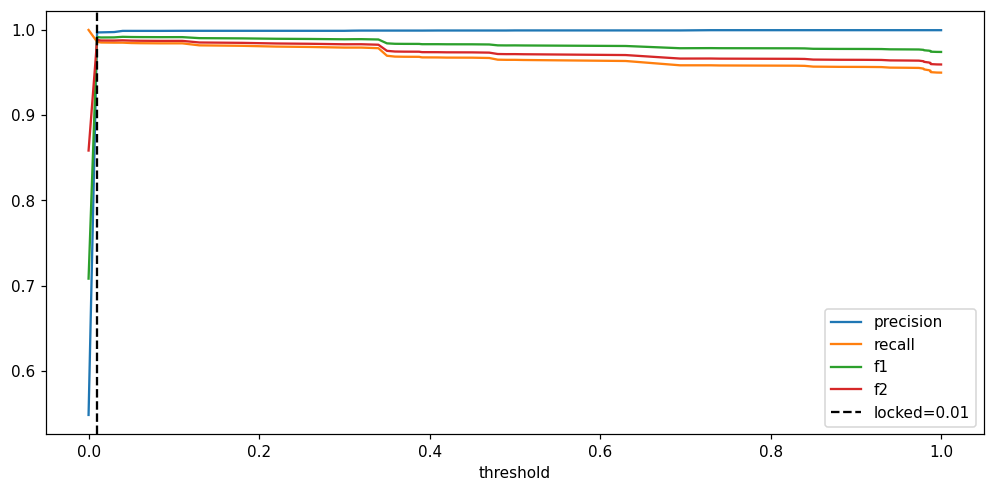

In [11]:
validation_score=decision_scores(model,X_validation)
unique_scores=np.unique(validation_score)
default_threshold=0.5 if hasattr(model,'predict_proba') else 0.0
if len(unique_scores)<=1000:
    threshold_grid=unique_scores
    grid_strategy='all unique scores'
else:
    threshold_grid=np.unique(np.quantile(validation_score,np.linspace(0.001,0.999,999)))
    grid_strategy='score quantiles'
threshold_grid=np.unique(np.append(threshold_grid,default_threshold))
print(f'Score levels: {len(unique_scores):,} | strategy: {grid_strategy} | default: {default_threshold}')
threshold_rows=[]
for threshold in threshold_grid:
    p=(validation_score>=threshold).astype(int)
    threshold_rows.append({'threshold':float(threshold),'precision':precision_score(y_validation,p,zero_division=0),'recall':recall_score(y_validation,p,zero_division=0),'f1':f1_score(y_validation,p,zero_division=0),'f2':fbeta_score(y_validation,p,beta=2,zero_division=0)})
threshold_table=pd.DataFrame(threshold_rows).sort_values('threshold')
chosen=threshold_table.sort_values(['f2','recall','precision'],ascending=False).iloc[0]
locked_threshold=float(chosen.threshold)
display(threshold_table.sort_values('f2',ascending=False).head(10))
threshold_table.plot(x='threshold',y=['precision','recall','f1','f2'],figsize=(11,5)); plt.axvline(locked_threshold,color='black',ls='--',label=f'locked={locked_threshold:.4g}'); plt.legend(); plt.show()

## 11. Đánh giá Test đúng một lần
Siêu tham số và ngưỡng đã khóa. Kết quả Test chỉ dùng báo cáo cuối, không quay lại sửa thiết kế.

,TEST
accuracy,0.998659
precision,0.997575
recall,1.000000
f1,0.998786
f2,0.999514
roc_auc,0.999614
average_precision,0.999377


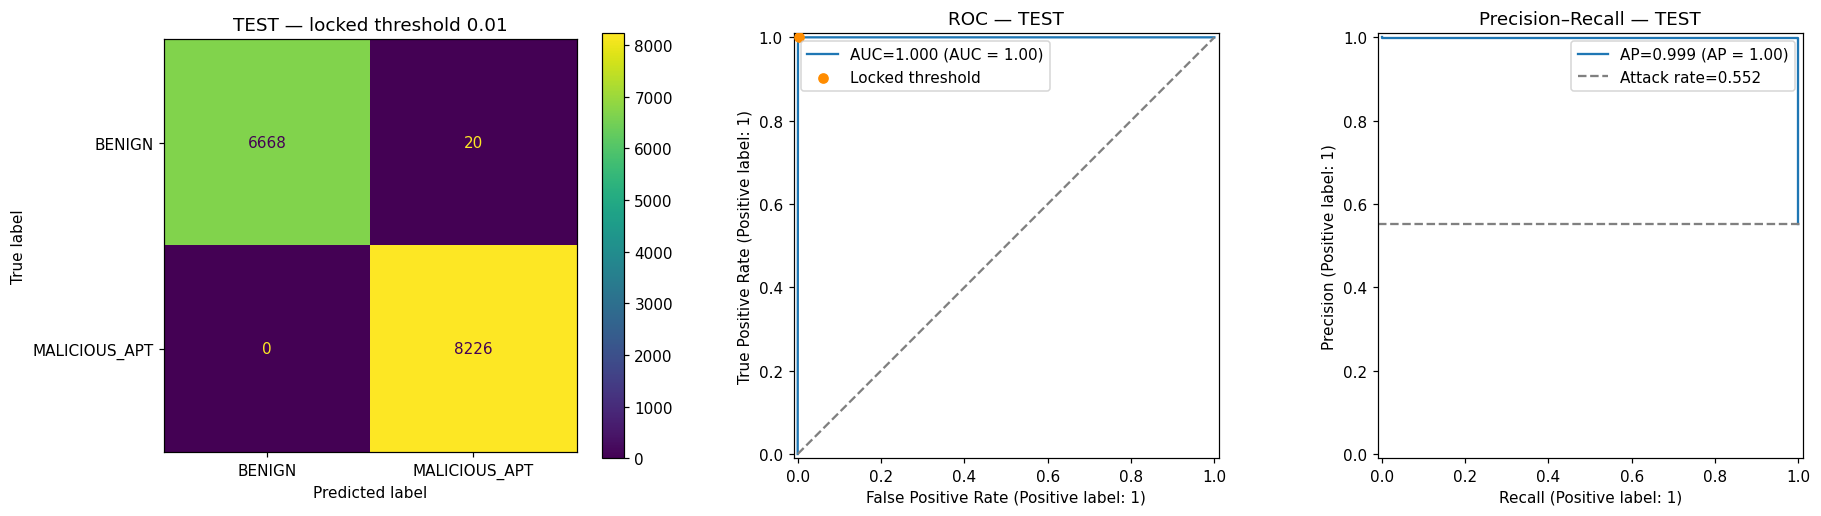

In [12]:
X_test,y_test=test.loc[:,MODEL_FEATURES],test[TARGET_COLUMN]
test_score=decision_scores(model,X_test)
test_pred=(test_score>=locked_threshold).astype(int)
test_result=pd.Series({'accuracy':accuracy_score(y_test,test_pred),'precision':precision_score(y_test,test_pred,zero_division=0),'recall':recall_score(y_test,test_pred,zero_division=0),'f1':f1_score(y_test,test_pred,zero_division=0),'f2':fbeta_score(y_test,test_pred,beta=2,zero_division=0),'roc_auc':roc_auc_score(y_test,test_score),'average_precision':average_precision_score(y_test,test_score)})
display(test_result.to_frame('TEST'))
tn,fp,fn,tp=confusion_matrix(y_test,test_pred,labels=[0,1]).ravel()
fig,axes=plt.subplots(1,3,figsize=(17,4.8))
ConfusionMatrixDisplay.from_predictions(y_test,test_pred,display_labels=['BENIGN','MALICIOUS_APT'],ax=axes[0]); axes[0].set_title(f'TEST — locked threshold {locked_threshold:.4g}')
RocCurveDisplay.from_predictions(y_test,test_score,name=f"AUC={test_result['roc_auc']:.3f}",ax=axes[1]); axes[1].plot([0,1],[0,1],'--',color='gray'); axes[1].scatter([fp/(fp+tn)],[tp/(tp+fn)],color='darkorange',zorder=5,label='Locked threshold'); axes[1].set_title('ROC — TEST'); axes[1].legend()
PrecisionRecallDisplay.from_predictions(y_test,test_score,name=f"AP={test_result['average_precision']:.3f}",ax=axes[2]); axes[2].axhline(float(y_test.mean()),ls='--',color='gray',label=f'Attack rate={y_test.mean():.3f}'); axes[2].set_title('Precision–Recall — TEST'); axes[2].legend(); plt.tight_layout(); plt.show()

## 12. Khoảng bất định bằng bootstrap
Bootstrap trên Test chỉ để mô tả độ bất định, không huấn luyện hoặc chọn ngưỡng lại.

In [13]:
rng=np.random.default_rng(SEED); boot=[]
y_array=y_test.to_numpy()
for _ in range(300):
    idx=rng.integers(0,len(y_array),len(y_array))
    if np.unique(y_array[idx]).size<2: continue
    boot.append({'f2':fbeta_score(y_array[idx],test_pred[idx],beta=2,zero_division=0),'roc_auc':roc_auc_score(y_array[idx],test_score[idx]),'average_precision':average_precision_score(y_array[idx],test_score[idx])})
boot=pd.DataFrame(boot)
display(pd.DataFrame({'estimate':test_result[['f2','roc_auc','average_precision']], 'ci_2.5%':boot.quantile(.025), 'ci_97.5%':boot.quantile(.975)}))

,estimate,ci_2.5%,ci_97.5%
f2,0.999514,0.999321,0.999709
roc_auc,0.999614,0.999310,0.999912
average_precision,0.999377,0.998877,0.999867


## 13. Lưu kết quả thực nghiệm
Lưu model, ngưỡng, split hash và metric để notebook so sánh tổng hợp có thể kiểm tra nguồn gốc.

In [14]:
experiment_dir=ROOT/'reports'/'notebook_experiments'; experiment_dir.mkdir(parents=True,exist_ok=True)
slug='04_bagging'
joblib.dump(model,experiment_dir/f'{slug}.joblib')
validation_locked_pred=(validation_score>=locked_threshold).astype(int)
validation_locked=pd.Series({'accuracy':accuracy_score(y_validation,validation_locked_pred),'precision':precision_score(y_validation,validation_locked_pred,zero_division=0),'recall':recall_score(y_validation,validation_locked_pred,zero_division=0),'f1':f1_score(y_validation,validation_locked_pred,zero_division=0),'f2':fbeta_score(y_validation,validation_locked_pred,beta=2,zero_division=0),'roc_auc':roc_auc_score(y_validation,validation_score),'average_precision':average_precision_score(y_validation,validation_score)})
record={'schema_version':2,'model':model_name,'best_params':search.best_params_,'cv_best_f2':float(search.best_score_),'locked_threshold':locked_threshold,'split_hash':split_hash,'validation_default_threshold':{k:float(v) for k,v in result.items()},'validation_locked_threshold':{k:float(v) for k,v in validation_locked.items()},'test_locked_threshold':{k:float(v) for k,v in test_result.items()}}
(experiment_dir/f'{slug}.json').write_text(json.dumps(record,indent=2),encoding='utf-8')
record

{'schema_version': 2,
 'model': 'bagging',
 'best_params': {'model__max_samples': 0.7, 'model__n_estimators': 100},
 'cv_best_f2': 0.986000561908449,
 'locked_threshold': 0.01,
 'split_hash': 'c20123f0928c7b1d625d87e7486b823dea3e8f29eebfd5db7fad48c8f3662a7c',
 'validation_default_threshold': {'accuracy': 0.9803727200634417,
  'precision': 0.9994378864530635,
  'recall': 0.9647314161692893,
  'f1': 0.9817780231916069,
  'f2': 0.9714785269369468,
  'roc_auc': 0.9928270044830522,
  'average_precision': 0.9934098393213295},
 'validation_locked_threshold': {'accuracy': 0.9908306899286281,
  'precision': 0.9971650663008688,
  'recall': 0.9860734310001809,
  'f1': 0.9915882326194698,
  'f2': 0.9882719741874672,
  'roc_auc': 0.9928270044830522,
  'average_precision': 0.9934098393213295},
 'test_locked_threshold': {'accuracy': 0.9986589781413437,
  'precision': 0.9975745816153286,
  'recall': 1.0,
  'f1': 0.9987858183584264,
  'f2': 0.9995139732685298,
  'roc_auc': 0.9996135815427103,
  'averag

## 14. Kết luận
So sánh chính thức ở `08_Lua_Chon_Mo_Hinh_Va_Bao_Cao.ipynb`. Giới hạn: nhãn rule-derived, dữ liệu mô phỏng Windows APT và chưa phải bằng chứng hiệu năng production.

## Cập nhật pipeline dữ liệu hợp nhất

Notebook này thuộc bộ thí nghiệm SecuraAI mới. Có hai tầng kết quả cần phân biệt:

- **Thí nghiệm giảng dạy 00–10:** so sánh thuật toán trên cùng split Windows-APT để bảo đảm công bằng.
- **Baseline hợp nhất theo từng event:** Windows-APT 2025 + RADAR + log Wazuh đã bộc lộ domain shift khi test trực tiếp.
- **Ứng viên temporal hiện tại:** dùng dữ liệu sự kiện đã chuẩn hóa cùng thống kê hành vi ở các cửa sổ 1, 5, 15 và 60 phút.
- **Luồng triển khai AI:** ML sàng lọc nhanh; chỉ trường hợp vượt ngưỡng Validation mới chuyển sang Foundation-Sec để phân tích ngữ cảnh.
- **Quyết định cuối:** `BENIGN` không tạo alert, `SUSPICIOUS` chờ điều tra, `MALICIOUS` mới tạo hoặc gộp alert. Luồng AI đang bật không sử dụng baseline 7 ngày hay luật cũ để tự quyết định alert.

RADAR bổ sung ground truth ransomware/Sysmon theo từng mẫu thực thi. Log Wazuh hiện tại chỉ là kiểm thử lab và weak-benign; không được trình bày như bằng chứng production. Test, threshold và dữ liệu ngoài miền được giữ tách biệt để giảm leakage.

In [15]:
import pandas as pd

combined_artifact_dir = ROOT / 'artifacts-combined-candidate'
combined_metadata_path = combined_artifact_dir / 'model_metadata.json'
combined_source_report_path = ROOT / 'reports' / 'combined_candidate_by_source.json'
temporal_artifact_dir = ROOT / 'artifacts-temporal-candidate'
temporal_metadata_path = temporal_artifact_dir / 'model_metadata.json'

if combined_metadata_path.exists():
    combined_metadata = json.loads(combined_metadata_path.read_text(encoding='utf-8'))
    display(pd.DataFrame({
        'value': [
            combined_metadata['selectedModel'],
            combined_metadata['lockedThreshold'],
            ', '.join(combined_metadata['datasets']),
            combined_metadata['test']['f2'],
            combined_metadata['test']['precision'],
            combined_metadata['test']['recall'],
        ]
    }, index=['selected_model','locked_threshold','datasets','combined_test_f2','combined_test_precision','combined_test_recall']))
else:
    print('Chưa có artifacts-combined-candidate. Chạy scripts/train_combined_candidate.py trước.')

if temporal_metadata_path.exists():
    temporal_metadata = json.loads(temporal_metadata_path.read_text(encoding='utf-8'))
    display(pd.DataFrame({
        'value': [
            temporal_metadata['selectedModel'], temporal_metadata['lockedThreshold'],
            temporal_metadata['validation']['f2'], temporal_metadata['test']['f2'],
            temporal_metadata['test']['falsePositiveRate'], temporal_metadata['status'],
        ]
    }, index=['temporal_model','temporal_threshold','validation_f2','test_f2','test_fpr','status']))
else:
    print('Chưa có artifacts-temporal-candidate. Chạy scripts/train_temporal_candidate.py trước.')


,value
selected_model,logistic_regression
locked_threshold,0.442104
datasets,"Windows-APT 2025 v4, RADAR v0.0.1-beta"
combined_test_f2,0.994966
combined_test_precision,0.990039
combined_test_recall,0.996205


,value
temporal_model,bagging
temporal_threshold,0.5
validation_f2,1.0
test_f2,1.0
test_fpr,0.0
status,EXPERIMENTAL_CONTROLLED_LAB_ONLY
